<a href="https://colab.research.google.com/github/Muskan-Sh-23/Machine-learning/blob/main/Decision_Tree/DecisionTreeRegressor_using_Sklearn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression Tree by Sklearn


In [15]:
#Importing Libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import fetch_california_housing   #DATASET
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [16]:
data = fetch_california_housing()
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

df["Target"] = data.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [17]:
X = data.data
y = data.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", data.feature_names)

X shape: (20640, 8)
y shape: (20640,)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [18]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [19]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


In [20]:
model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42    # We did exactly the same configuration in this model as our scratch model.
)

In [21]:
#Train the model
model.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=5, random_state=42)

In [22]:
y_pred = model.predict(X_test)

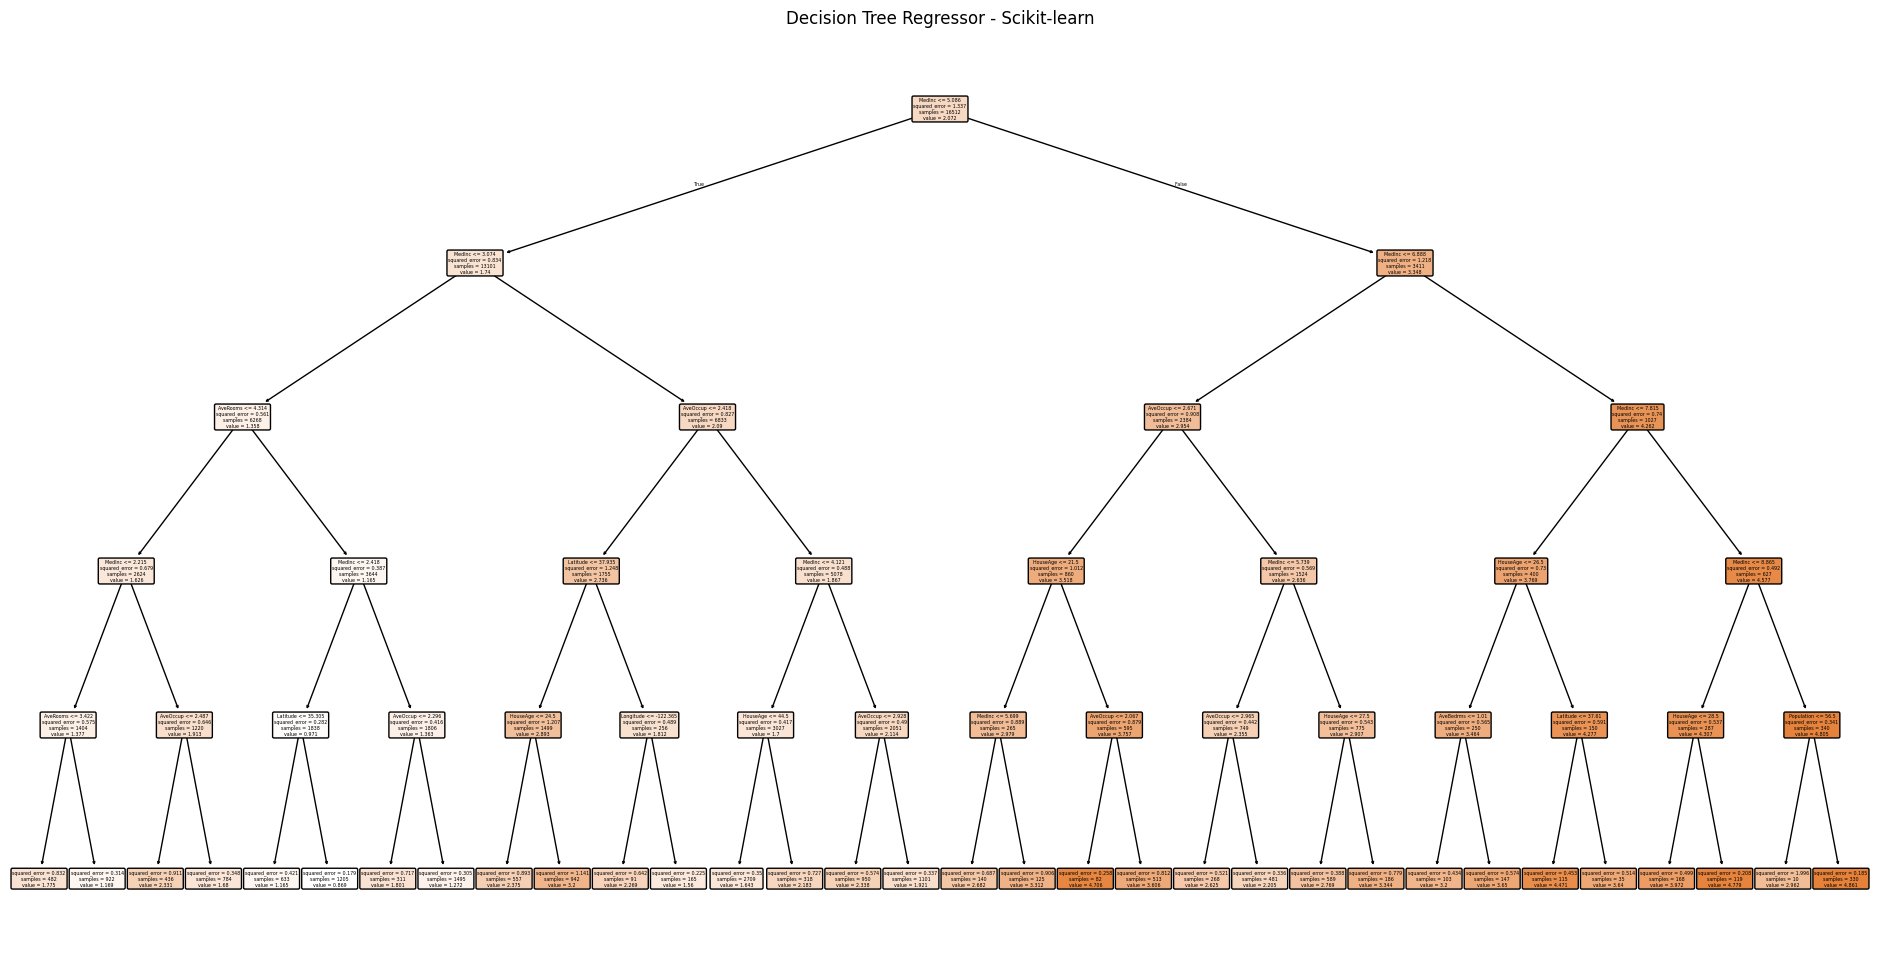

In [23]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=data.feature_names,
    filled=True,
    rounded=True
)

plt.title("Decision Tree Regressor - Scikit-learn")
plt.show()

In [24]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.5245146178314735


In [25]:
# Evaluation
r2 = r2_score(y_test, y_pred)

print("Decision Tree Regression Results")

print("MSE:", mse)
print("R² Score:", r2)

Decision Tree Regression Results
MSE: 0.5245146178314735
R² Score: 0.5997321244428706


## Comparison with From-Scratch Implementation

To validate our implementation, we trained `sklearn`'s `DecisionTreeRegressor` using the **same California Housing dataset, train-test split, and `max_depth=5`**.

### Results

| Model | MSE | R² Score |
|---|---:|---:|
| From Scratch | 0.5245 | 0.5997 |
| Scikit-learn | 0.5245 | 0.5997 |

The results are essentially identical.

This shows that our **from-scratch implementation successfully reproduced the behavior of a Decision Tree Regressor** under the same configuration.

The goal of using `sklearn` here was not to get a higher score, but to **validate our implementation against a standard library implementation**.